In [ ]:
from pathlib import Path
import string
import numpy as np
import geopandas as gpd
import rasterio as rio
import pyproj
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FormatStrFormatter
from cartopy import feature as cf
from cartopy import crs as ccrs
import cartopy.io.shapereader as shpreader

plt.rcParams['font.family'] = 'Arial'   # manuscript house font

In [ ]:
# ---------------------------------------------------------------------------
# CONFIG — paths + the two scenarios this figure compares.
# ---------------------------------------------------------------------------
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

RES      = '50km'
DR       = 'DM-RM'    # central demand/reserve case
AR       = 'M'
BETA_BAU = 0.00       # BAU  = scenario BAU at beta 0.00
BETA_CON = 0.7       # CON  = scenario BAU at beta 0.70 (conservation-siting knee)

def asr_tif(beta):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-BAU-B{beta:.2f}-{RES}-{DR}-A{AR}.tif'
def mine_tif(beta):
    return RESULTS / 'mining-area' / f'mining-area-expansion-2050-BAU-B{beta:.2f}-{RES}-{DR}-A{AR}.tif'

COUNTRY_RASTER = RESULTS / 'country-rasters' / f'country-raster-eck4-{RES}.tif'
RWR_RASTER     = RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif'
# Capital-city markers (zoom-ins): a local Natural Earth copy if present, else
# fetched via cartopy in the next cell. Loaded below as `capitals`.
CAPITALS_SHP   = DATA / 'ne_10m_populated_places' / 'ne_10m_populated_places.shp'

In [ ]:
# --- capital cities for the zoom-in markers + country raster -------------
# use a local Natural Earth copy if present, else fetch the bundled
# Natural Earth 'populated_places' via cartopy (auto-download + cache).
if CAPITALS_SHP.exists():
    populated_places = gpd.read_file(CAPITALS_SHP)
else:
    populated_places = gpd.read_file(
        shpreader.natural_earth(resolution='10m', category='cultural', name='populated_places'))
capitals = populated_places[populated_places['FEATURECLA'] == 'Admin-0 capital'].to_crs('ESRI:54012')
CAPITALS_AVAILABLE = len(capitals) > 0
print(f'capitals: {len(capitals)} Admin-0 capitals loaded')

country_raster_50km_ = rio.open(COUNTRY_RASTER)

capitals: 202 Admin-0 capitals loaded


In [ ]:
# --- rasters: BAU vs CON (= BAU at beta 0.70) ----------------------------
mining_biodiversity_overlap_BAU = rio.open(asr_tif(BETA_BAU)).read(1)
mining_biodiversity_overlap_CON = rio.open(asr_tif(BETA_CON)).read(1)

mining_area_expansion_BAU  = rio.open(mine_tif(BETA_BAU)).read(1)
mining_area_expansion_CON  = rio.open(mine_tif(BETA_CON)).read(1)

rarity_weighted_richness_50km = rio.open(RWR_RASTER).read(1)

overlap_change_CON = mining_biodiversity_overlap_BAU - mining_biodiversity_overlap_CON

In [ ]:
# --- shared boundary norm for the overlap-change panels -----------------
norm_ASR_change = BoundaryNorm([-0.05, -0.01, -1e-3, 0, 1e-3, 0.01, 0.05], 256)

In [ ]:
# --- zoom-in coordinate helpers (capital markers skipped when unavailable) ---
def _lonlat_to_eck4(lon, lat, src):
    proj = pyproj.Transformer.from_crs("EPSG:4326", src.crs.to_string(), always_xy=True)
    x, y = proj.transform(lon, lat)
    col, row = ~src.transform * (x, y)
    return int(row), int(col)

def _compute_extent(r1, r2, c1, c2, transform):
    x_ul = transform.c + c1 * transform.a
    y_ul = transform.f + r1 * transform.e
    x_lr = transform.c + c2 * transform.a
    y_lr = transform.f + r2 * transform.e
    return (x_ul, x_lr, y_lr, y_ul)

def _eck4_to_lonlat(x, y):
    proj_to_lonlat = pyproj.Transformer.from_crs("ESRI:54012", "EPSG:4326", always_xy=True)
    return proj_to_lonlat.transform(x, y)

def _fmt_lon(lon):
    return f"{abs(lon):.1f}°E" if lon >= 0 else f"{abs(lon):.1f}°W"
def _fmt_lat(lat):
    return f"{abs(lat):.1f}°N" if lat >= 0 else f"{abs(lat):.1f}°S"

def _capitals_in(xmin, xmax, ymin, ymax):
    if not CAPITALS_AVAILABLE:
        return None
    return capitals[(capitals.geometry.x >= xmin) & (capitals.geometry.x <= xmax) &
                    (capitals.geometry.y >= ymin) & (capitals.geometry.y <= ymax)]

In [ ]:
# --- generic zoom helper for the Extended-Data panel grid ---------------
def display_a_zoomin2(data, lon, lat, cmap, the_norm, axx):
    center_i, center_j = _lonlat_to_eck4(lon, lat, country_raster_50km_)
    r = 10
    slice_1 = data[center_i-r:center_i+r, center_j-r:center_j+r]
    display_extent = _compute_extent(center_i-r, center_i+r, center_j-r, center_j+r, country_raster_50km_.transform)
    xmin, xmax, ymin, ymax = display_extent
    cap = _capitals_in(xmin, xmax, ymin, ymax)
    axx.add_feature(cf.COASTLINE, linewidth=1.0)
    axx.add_feature(cf.BORDERS, linewidth=0.8, edgecolor='grey', zorder=10)
    if cap is not None and len(cap):
        axx.scatter(cap.geometry.x, cap.geometry.y, marker='*', s=100, edgecolor='k',
                    facecolor='yellow', alpha=1.0, transform=ccrs.EckertIV(), zorder=20)
    gg = axx.imshow(np.where(slice_1 == 0, np.nan, slice_1), cmap=cmap, interpolation='nearest',
                    norm=the_norm, origin='upper', extent=display_extent, zorder=0, alpha=1.0)
    n = 3
    xticks = np.linspace(display_extent[0], display_extent[1], n)
    yticks = np.linspace(display_extent[2], display_extent[3], n)
    axx.set_xticks(xticks); axx.set_yticks(yticks)
    axx.set_xticklabels([_fmt_lon(_eck4_to_lonlat(aa, display_extent[2])[0]) for aa in xticks], fontsize=8)
    axx.set_yticklabels([_fmt_lat(_eck4_to_lonlat(display_extent[0], aa)[1]) for aa in yticks], fontsize=8)
    return gg

norm_MA  = BoundaryNorm([0, 0.1, 0.5, 1, 5, 10, 30], 256)
norm_RWR = BoundaryNorm([0, 0.1, 0.5, 1, 5, 10, 37], 256)

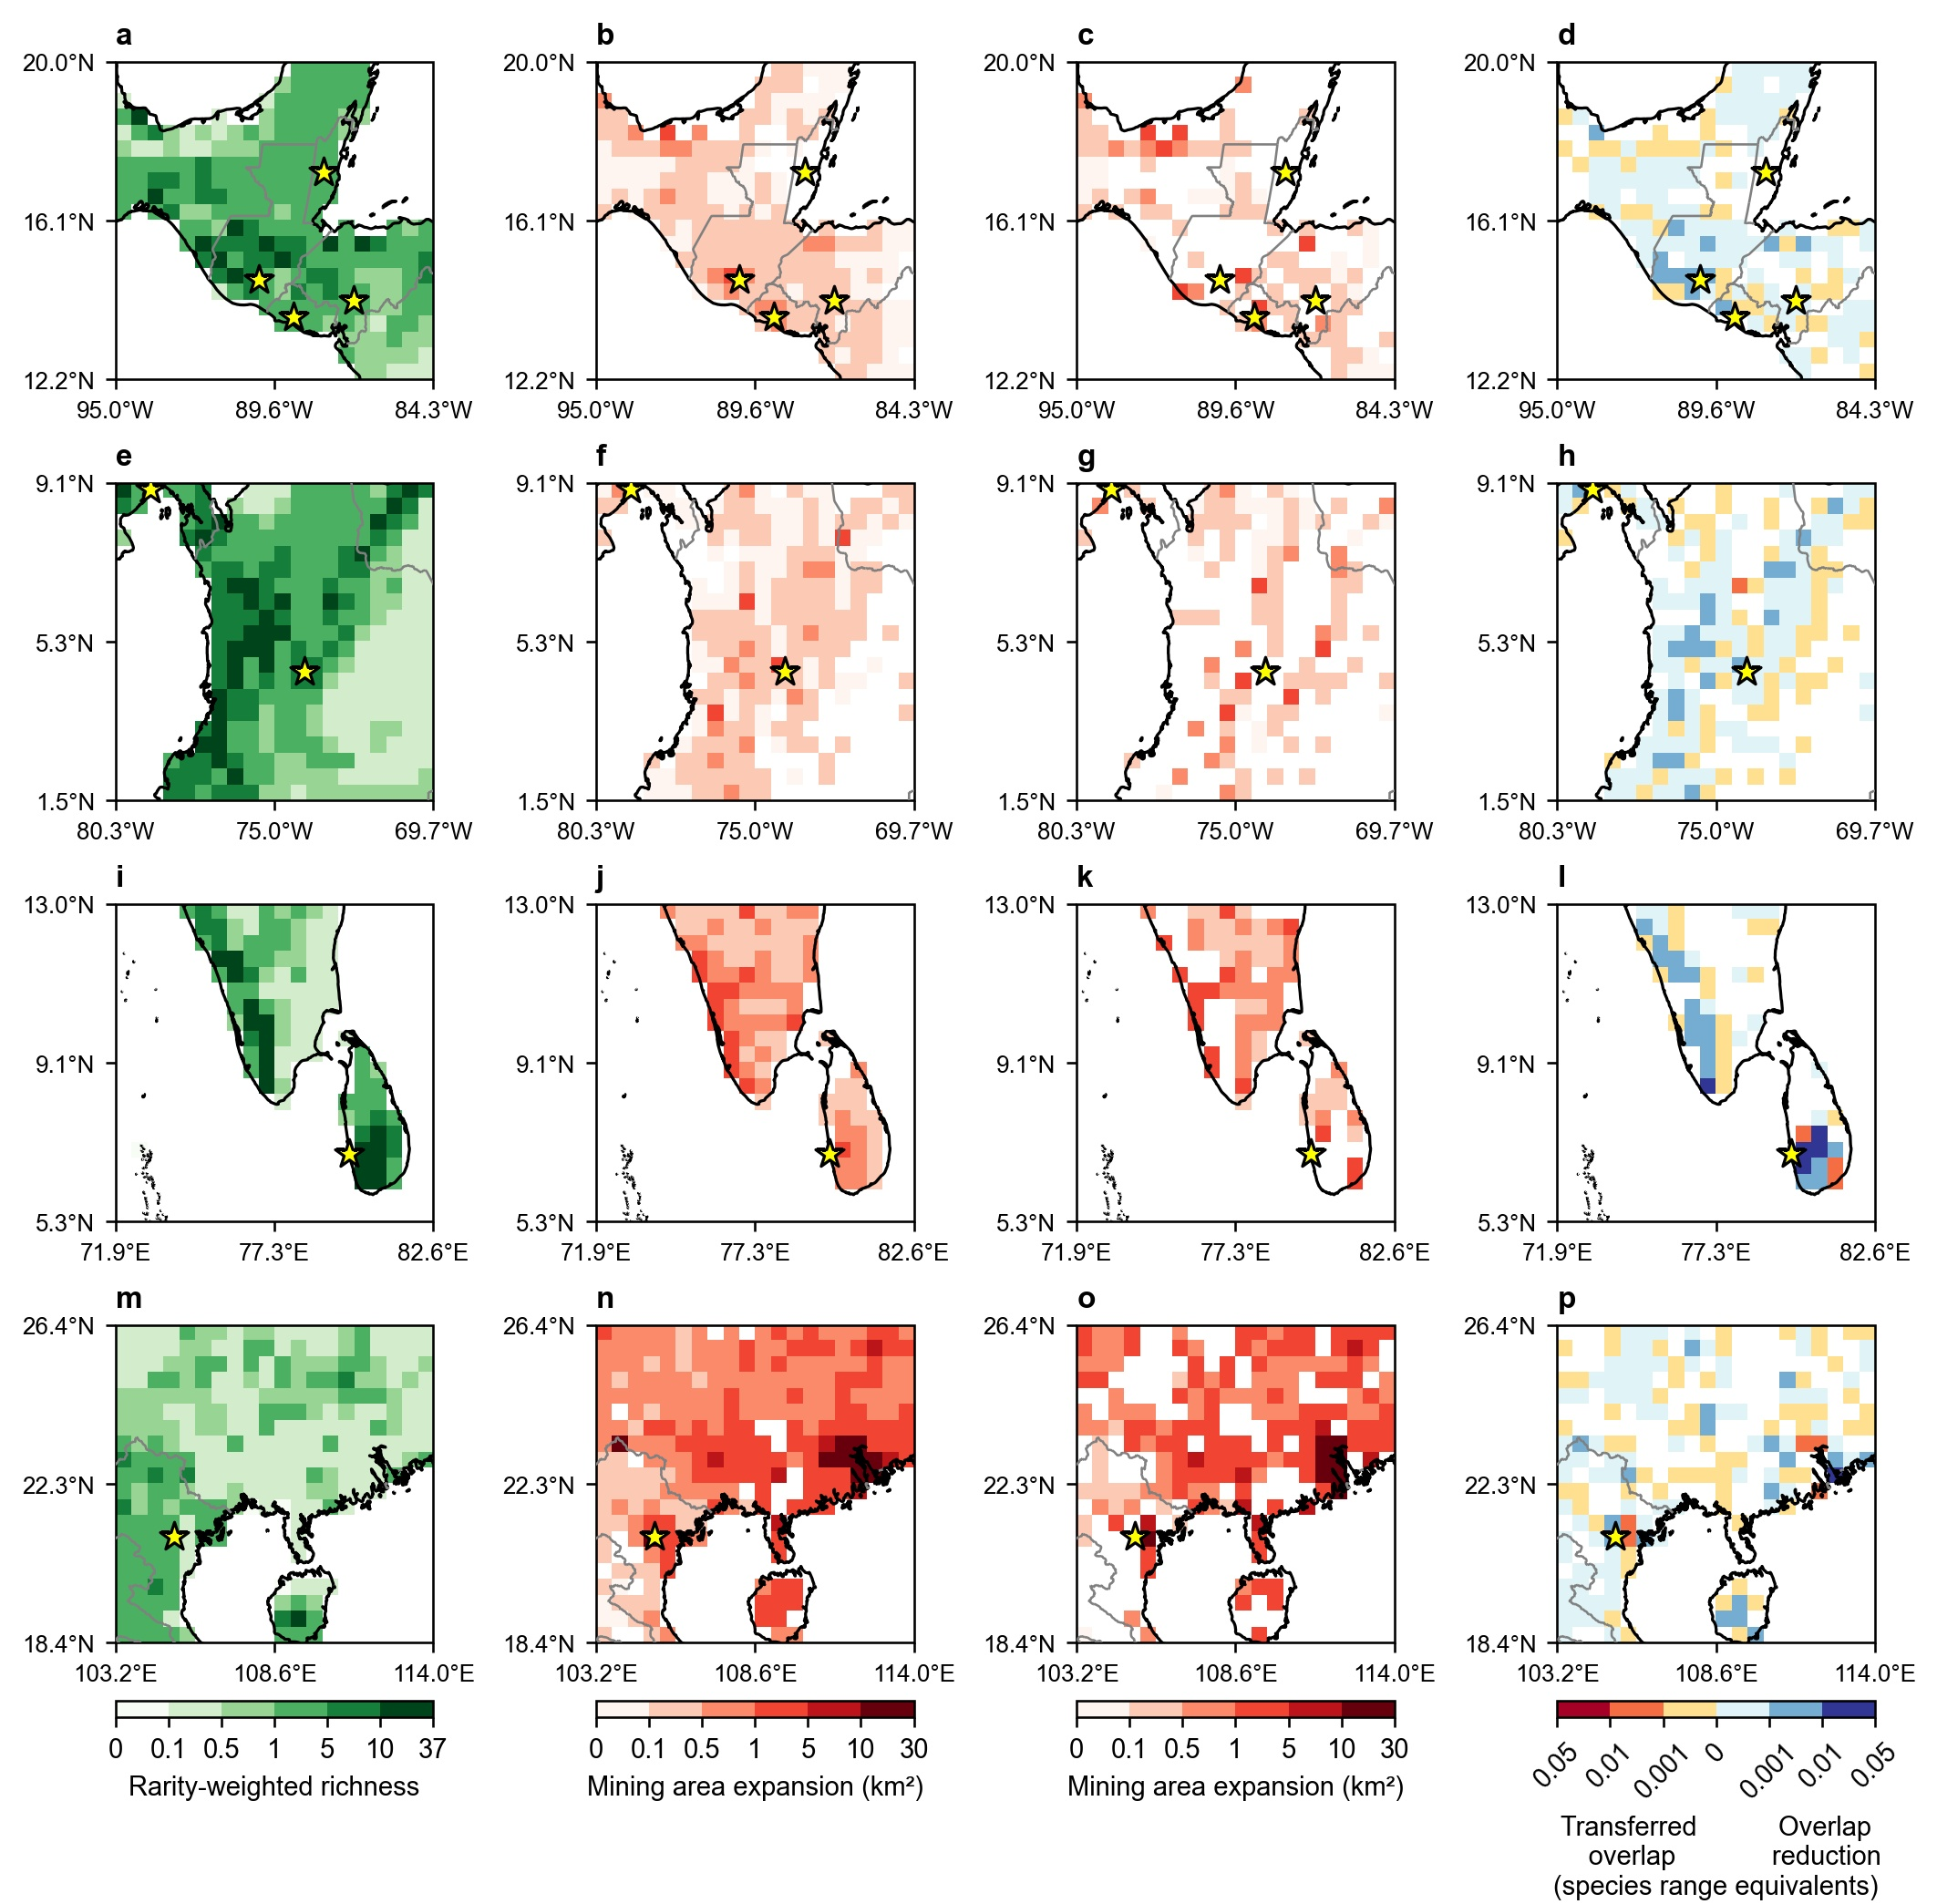

In [ ]:
# ===================== Extended Data Figure 5: focal-region grid ===========
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
labels = list(string.ascii_lowercase)
focal_points = [(-90, 16), (-75, 5), (78, 9), (110, 22)]

for i, points in enumerate(focal_points):
    ax1 = plt.subplot(4, 4, i*4+1, projection=ccrs.EckertIV())
    ax2 = plt.subplot(4, 4, i*4+2, projection=ccrs.EckertIV())
    ax3 = plt.subplot(4, 4, i*4+3, projection=ccrs.EckertIV())
    ax4 = plt.subplot(4, 4, i*4+4, projection=ccrs.EckertIV())
    gg = display_a_zoomin2(rarity_weighted_richness_50km, points[0], points[1], 'Greens', norm_RWR, ax1)
    hh = display_a_zoomin2(mining_area_expansion_BAU,     points[0], points[1], 'Reds',   norm_MA,  ax2)
    ii = display_a_zoomin2(mining_area_expansion_CON,     points[0], points[1], 'Reds',   norm_MA,  ax3)
    jj = display_a_zoomin2(overlap_change_CON,            points[0], points[1], 'RdYlBu', norm_ASR_change, ax4)
    for k, axk in enumerate([ax1, ax2, ax3, ax4]):
        axk.set_title(labels[i*4 + k], loc='left', weight='bold')

cbar1 = plt.colorbar(gg, orientation='horizontal', pad=0.05, fraction=0.05, label='Rarity-weighted richness')
cbar2 = plt.colorbar(hh, orientation='horizontal', pad=0.05, fraction=0.05, label='Mining area expansion (km²)')
cbar3 = plt.colorbar(ii, orientation='horizontal', pad=0.05, fraction=0.05, label='Mining area expansion (km²)')
cbar4 = plt.colorbar(jj, orientation='horizontal', pad=0.05, fraction=0.05, label='Transferred           Overlap\n     overlap             reduction\n(species range equivalents)')
cbar1.ax.xaxis.set_major_formatter(FormatStrFormatter('%.3g'))
for cb in (cbar2, cbar3, cbar4):
    cb.ax.xaxis.set_major_formatter(FormatStrFormatter('%.2g'))
cbar4.ax.set_xticklabels(['0.05', '0.01', '0.001', 0, 0.001, 0.01, 0.05])
for tick in cbar4.ax.get_xticklabels():
    tick.set_rotation(45)

# Keep the final width within 180 mm without distorting panel proportions.
# Embedded TrueType text; matching 300-dpi raster copies for Extended Data.
from final_figure_export import export_final_figure
export_report = export_final_figure(fig, FIGURES / 'Extended-Data-Figure-5', jpg_dpi=300)
